## 07. Задача распознавания текста на изображениях

`Что такое механизм внимания и откуда он появился?`

Механизм внимания был впервые предложен в 2014 году в работе "Neural Machine Translation by Jointly Learning to Align and Translate" (Bahdanau et al., 2014). Он был разработан для улучшения нейронных машинных переводов — задачи, в которой одна последовательность (например, предложение на английском) должна быть переведена на другую (например, на французский).

До появления внимания архитектуры `Seq2Seq` работали так: энкодер преобразовывал входную последовательность в один фиксированный вектор, а затем декодер генерировал выходной текст, основываясь только на этом векторе. Это работало плохо для длинных предложений, потому что информация "сжималась" слишком сильно.

<img src="...
" alt="drawing" width="1200"/>

`Идея механизма внимания`

Механизм внимания позволяет декодеру "смотреть" на разные части входного предложения по мере генерации каждого слова, вместо того чтобы опираться только на один вектор. То есть он "взвешивает" выходы энкодера и решает, где сосредоточиться в данный момент.

❝Механизм внимания — это способ дать модели фокусироваться на самых релевантных участках входа при генерации каждого выхода.❞

<img src="...
SUVORK5CYII=
" alt="drawing" width="1200"/>

После успеха в машинном переводе, внимание стали использовать во многих задачах.

### Формулировка подхода к решению задачи

Задача распознавания текста с изображения формулируется как задача генерации последовательности символов по входному изображению.
Модель обучается сопоставлять визуальные признаки изображения с текстовым представлением, символ за символом.

Подход:

- Энкодер (CNN + BiLSTM) — извлекает визуальные и контекстные признаки из изображения.

- Механизм внимания — помогает декодеру фокусироваться на нужной части признаков при генерации каждого символа.

- Декодер (RNN/GRU) — поэтапно генерирует выходной текст, начиная с символа начала последовательности (\<SOS\>), до конца (\<EOS\>).

<img src="...
" alt="drawing" width="1200"/>

### Программная реализация модели

Импортируем требуемые модули

In [3]:
import torch.nn.functional as F
import plotly.graph_objs   as go
import torch.optim         as optim
import torch.nn            as nn
import numpy               as np

import torch
import json
import os

from plotly.subplots import make_subplots
from tqdm            import tqdm

Реализуем загрузчик данных

In [7]:
from torchvision.transforms.v2 import Resize, ToDtype, ToImage, Normalize, Compose
from string                    import digits, ascii_uppercase, ascii_lowercase
from torch.utils.data          import Dataset, DataLoader
from PIL                       import Image

In [ ]:
# !mkdir -p data
# !gdown 1gRIBd-yxvBK4fFqUmXRqZcTkCnGHgq5c
# # !curl https://files.culab.ru/files/public/DeepLearningAdvanced/seminars/seminar_crnn_data.zip -o seminar_crnn_data.zip

# !unzip -o seminar_crnn_data.zip -d data >/dev/null
# !rm seminar_crnn_data.zip

In [8]:
PATH_TO_DATA = "./data/"  # Change to your path with unzipped data

config_path = os.path.join(PATH_TO_DATA, "config.json")
images_path = os.path.join(PATH_TO_DATA, "images")

assert os.path.isfile(config_path)
assert os.path.isdir (images_path)

with open(config_path, "rt") as fp:
    config = json.load(fp)

config_full_paths = []
for item in config:
    config_full_paths.append({"file": os.path.join(images_path, item["file"]),
                              "text": item["text"]})
config = config_full_paths

print("Total items in data:", len(config))
print("First 3 items:")
for item in config[:3]:
    print(item)

Total items in data: 41141
First 3 items:
{'file': './data/images\\ru_typenomer7_180509_o_11307847.jpg', 'text': '8090TB76'}
{'file': './data/images\\ru_typenomer2_190509_o_12834692.jpg', 'text': 'BA428416'}
{'file': './data/images\\ru_typenomer12_160328_o_8249929.jpg', 'text': 'AA509A25'}


`RecognitionDataset` загружает изображения и соответствующие текстовые метки, преобразует текст в последовательности индексов и применяет требуемые преобразования к изображениям.

In [9]:
class RecognitionDataset(Dataset):
    
    # Базовый алфавит (A-Z, 0-9) начинается с индекса 3
    _default_base_alphabet = { item : index + 3 for index, item in enumerate( digits + ascii_uppercase ) }
    
    # Специальные токены: начало, конец последовательности и паддинг
    _default_util_alphabet = {'<SOS>': 0, '<EOS>': 1, '<PAD>': 2 }
    
    # Объединение служебных и базовых токенов в полный алфавит
    _default_full_alphabet = { **_default_util_alphabet, **_default_base_alphabet }
    
    # Преобразования изображений по умолчанию
    _default_transform = Compose([
        ToImage(),  # Преобразование в формат PIL → tensor
        ToDtype(torch.float32, scale=True),  # Приведение к float32 и масштабирование в [0, 1]
        Resize(size=(32, 160)),  # Масштабирование изображения к заданному размеру
        Normalize(mean=[0.485, 0.456, 0.406],  # Нормализация (значения, как в ImageNet)
                  std=[0.229, 0.224, 0.225])
    ])
    
    @staticmethod
    def _compute_mask(text):
        """
        Возвращает маску по тексту:
        - 'D' для цифры
        - 'L' для заглавной буквы
        Пример: 'A123BC45' → 'LDDDLLDD'
        Если в тексте есть недопустимые символы, возвращает None
        """
        mask = []
        for char in text:
            if char in digits:
                mask.append("D")
            elif char in ascii_uppercase:
                mask.append("L")
            else:
                return None
        return "".join(mask)

    @staticmethod
    def _filter_markup(source_markup, alphabet, mask_s):
        """
        Фильтрует исходную разметку:
        - Только символы, входящие в алфавит
        - Только строки, соответствующие допустимым шаблонам маски
        """
        target_markup = []
        for item in tqdm(source_markup):
            text = item["text"]
            mask = RecognitionDataset._compute_mask(text)
            if np.all([char in alphabet for char in text]) and (mask in mask_s):
                target_markup.append({"file": item["file"], "text": item["text"]})
        return target_markup

    def _process_markup(self, markup_filepath, images_path, alphabet, mask_s):
        """
        Загружает и фильтрует аннотации, добавляет путь к файлам изображений
        """
        with open(markup_filepath, "rt") as fp:
            source_markup = json.load(fp)

        filtered_markup = RecognitionDataset._filter_markup(source_markup, alphabet, mask_s)

        target_markup = []
        for item in filtered_markup:
            target_markup.append({
                "file": os.path.join(images_path, item["file"]),  # Полный путь к изображению
                "text": item["text"]
            })

        return target_markup

    def text_to_tensor(self, text):
        """
        Преобразует строку в тензор индексов:
        [<SOS>, char1, char2, ..., charN, <EOS>]
        Недопустимые символы заменяются на <PAD>
        Обрезается до max_seq_len
        """
        index_s = [self.alphabet['<SOS>']] + \
                  [self.alphabet.get(ch, self.alphabet['<PAD>']) for ch in text.upper()] + \
                  [self.alphabet['<EOS>']]
        return torch.tensor(index_s[:self.max_seq_len], dtype=torch.long)

    def __init__(self, images_path, markup_filepath, transform=None, alphabet=None, max_seq_len=11):
        """
        Инициализация датасета:
        - images_path:     путь к изображениям
        - markup_filepath: путь к JSON-разметке
        - transform:       преобразования изображений
        - alphabet:        словарь символ → индекс
        - max_seq_len:     максимальная длина последовательности
        """
        self.markup_filepath = markup_filepath
        self.images_path     = images_path
        self.max_seq_len     = max_seq_len

        self.transform = transform or self._default_transform 
        self.alphabet  = alphabet  or self._default_full_alphabet
        
        # Допустимые шаблоны для текста (например, маска для госномера)
        self.mask_s = ["LDDDLLDD", "LDDDLLDDD"]

        # Предобработка аннотаций и сохранение валидных примеров
        self.sample_s = self._process_markup(markup_filepath, images_path, self.alphabet, self.mask_s)

    def __len__(self):
        """
        Возвращает:
        - Общий размер набора данных
        """
        return len(self.sample_s)

    def __getitem__(self, idx):
        """
        Возвращает:
        - Преобразованное изображение
        - Тензор индексов текста
        - Исходный текст (для удобства)
        """
        image_filepath = self.sample_s[idx]['file']
        text           = self.sample_s[idx]['text']
        
        source_image = Image.open(image_filepath)
        target_image = self.transform(source_image)
        label_tensor = self.text_to_tensor(text)
        return target_image, label_tensor, text


Реализуем функцию пакетирования данных

In [10]:
class recognition_collate_fn:
    def __init__(self, pad_index):
        self.pad_index = pad_index
    def __call__(self, batch):
        image_s, label_s, text_s = zip(*batch)

        image_s = torch.stack(image_s)

        max_len = max(label.size(0) for label in label_s)
        padded_labels = torch.full( [len(label_s), max_len], self.pad_index, dtype=torch.long)

        for i, label in enumerate(label_s):
            padded_labels[i, :label.size(0)] = label

        return image_s, padded_labels, text_s

Создадим пакетированный загрузчик данных

In [11]:
from torch.utils.data import random_split

markup_filepath = 'data/config.json'
images_dirpath  = 'data/images'

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Алфавит символов, при кодировании текста необходимо иметь прямое преобразование символ->индекс, 
# при декодировании результата иметь обратное преобразование индекс->символ
util_alphabet = {'<SOS>':0, '<EOS>':1, '<PAD>':2 }
base_alphabet = { item : index + len(util_alphabet) for index, item in enumerate( digits + ascii_uppercase ) }
full_alphabet_s2i = { **util_alphabet, **base_alphabet }
full_alphabet_i2s = { v: k for k, v in full_alphabet_s2i.items()}

#Для удобства мы зохраняем индексы сервисных символов
sos_idx = full_alphabet_s2i['<SOS>']
eos_idx = full_alphabet_s2i['<EOS>']
pad_idx = full_alphabet_s2i['<PAD>']

alphabet_size = len(full_alphabet_s2i)
# 2. Создаем загрузчик данных
generator = torch.Generator().manual_seed(42)

full_dataset = RecognitionDataset(images_dirpath, markup_filepath)
train_dataset, val_dataset = random_split(full_dataset, [0.8, 0.2])
# 3. Создаем загрузчик пакетированных данных
train_batch_size = 16
val_batch_size   = 1

train_dataloader = DataLoader(train_dataset, batch_size=train_batch_size, shuffle=True, collate_fn=recognition_collate_fn(full_alphabet_s2i['<PAD>']) )
val_dataloader   = DataLoader(val_dataset  , batch_size=val_batch_size  , shuffle=True, collate_fn=recognition_collate_fn(full_alphabet_s2i['<PAD>']) )

100%|██████████| 41141/41141 [00:00<00:00, 181776.66it/s]


Создаем модель согласно представленной выше архитектуры

`CRNN_Encoder`

Извлекает последовательные признаки из изображения (визуальные признаки по ширине изображения). Состоит из сверточных слоёв (CNN) и LSTM (RNN).

In [12]:
class CRNN_Encoder(nn.Module):
    def __init__(self, input_channels, hidden_size, input_height):
        super(CRNN_Encoder, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(input_channels, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2),                                     # H/2 x W/2
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2),                                     # H/4 x W/4
        )

        # Compute feature height after CNN
        cnn_output_channels = 128
        cnn_feature_height = input_height // 4
        rnn_input_size = cnn_output_channels * cnn_feature_height

        self.rnn = nn.LSTM(rnn_input_size, hidden_size, bidirectional=True, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.size()
        x = self.cnn(x)  # (B, C, H, W)
        x = x.permute(0, 3, 1, 2)  # (B, W, C, H)
        x = x.contiguous().view(b, x.size(1), -1)  # (B, W, C*H)
        outputs, (hn, cn) = self.rnn(x)
        return outputs, (hn, cn)

`BahdanauAttention`

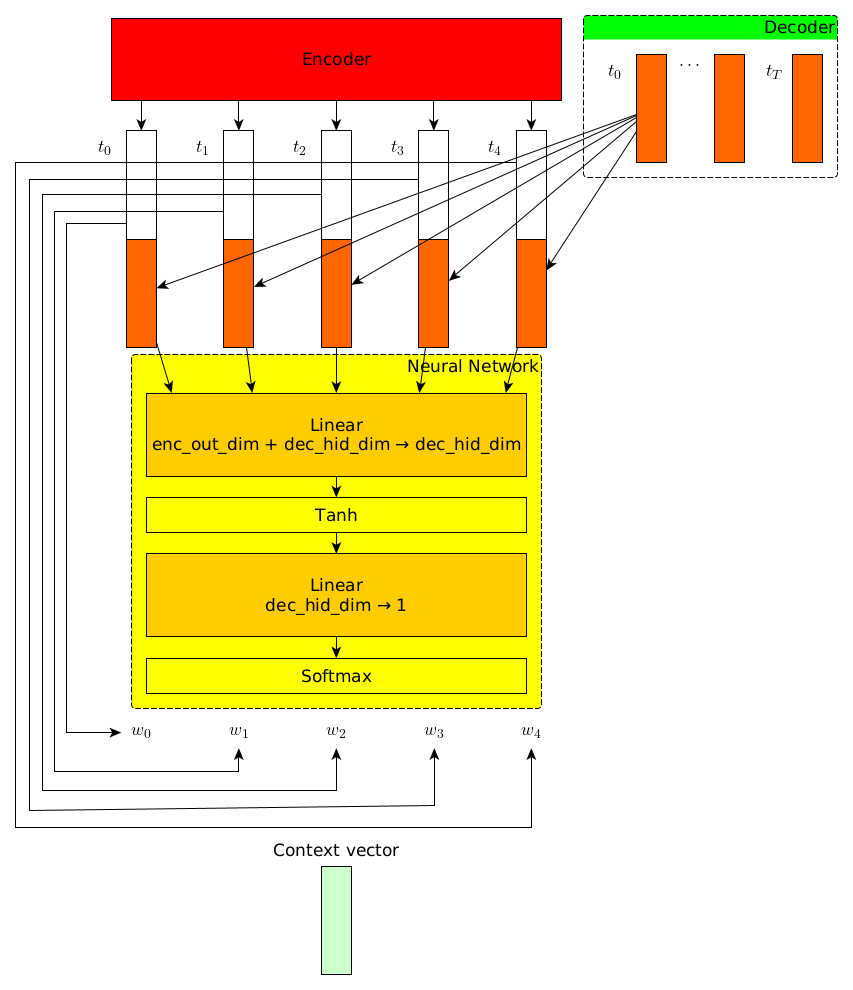

In [13]:
class BahdanauAttention(nn.Module):
    def __init__(self, encoder_hidden_dim, decoder_hidden_dim):
        super(BahdanauAttention, self).__init__()
        self.attn = nn.Linear(encoder_hidden_dim + decoder_hidden_dim, decoder_hidden_dim)
        self.v = nn.Linear(decoder_hidden_dim, 1, bias=False)

    def forward(self, hidden, encoder_outputs):
        # hidden: (B, D), encoder_outputs: (B, T, H)
        B, T, H = encoder_outputs.size()
        hidden = hidden.unsqueeze(1).repeat(1, T, 1)  # (B, T, D)
        energy = torch.tanh(self.attn(torch.cat((hidden, encoder_outputs), dim=2)))  # (B, T, D)
        attention = self.v(energy).squeeze(2)  # (B, T)
        return F.softmax(attention, dim=1)

In [14]:
batch_size, seq_len = 1, 10
encoder_hidden_dim = 32
decoder_hidden_dim = 32

# Create fake data
encoder_outputs = torch.randn(batch_size, seq_len, encoder_hidden_dim)
decoder_hidden = torch.randn(batch_size, decoder_hidden_dim)

# Instantiate and run attention
attention = BahdanauAttention(encoder_hidden_dim, decoder_hidden_dim)
attn_weights = attention(decoder_hidden, encoder_outputs)

# ---- Assertions ----
print("Attention output shape:", attn_weights.shape)  # (B, T)
assert attn_weights.shape == (batch_size, seq_len), "Output shape mismatch"
assert torch.allclose(attn_weights.sum(dim=1), torch.ones(batch_size), atol=1e-5), "Softmax normalization failed"
assert attn_weights.requires_grad, "Gradients not enabled"
# ---- Gradient check ----
attn_weights.sum().backward()
for name, param in attention.named_parameters():
    assert param.grad is not None, f"No gradient for parameter {name}"
print("✅ BahdanauAttention passed all tests.")

Attention output shape: torch.Size([1, 10])
✅ BahdanauAttention passed all tests.


`LuongAttention`

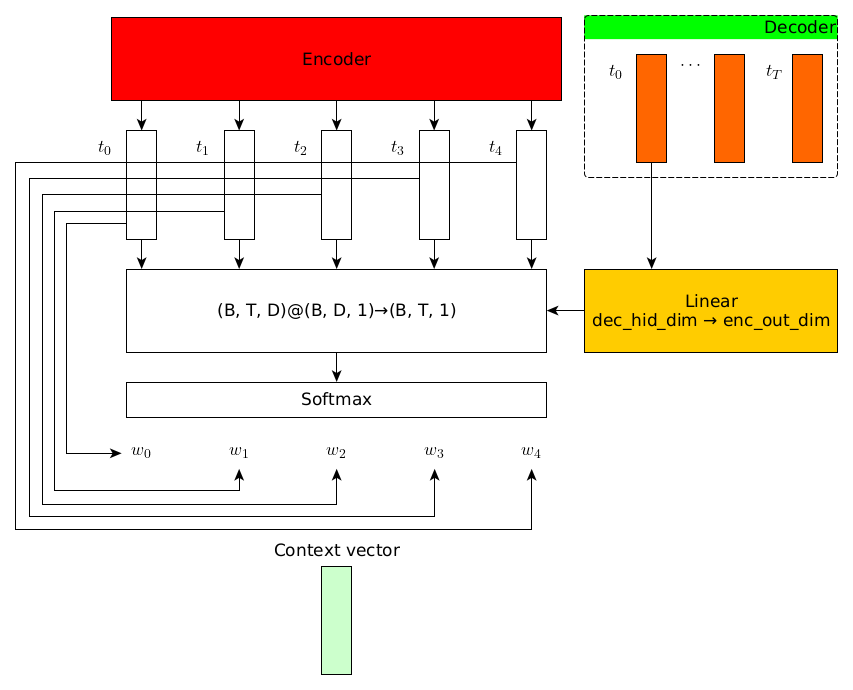

In [15]:
class LuongAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim):
        super().__init__()
        self.linear = nn.Linear(decoder_dim, encoder_dim, bias=False)

    def forward(self, decoder_hidden, encoder_outputs):
        # decoder_hidden: (B, H)
        # encoder_outputs: (B, T, H)
        scores = torch.bmm(
            encoder_outputs,
            self.linear(decoder_hidden).unsqueeze(2)
        ).squeeze(2)  # (B, T)
        attn_weights = F.softmax(scores, dim=1)
        return attn_weights

In [16]:
batch_size, seq_len = 1, 10
hidden_dim = 32
# Fake encoder and decoder states
encoder_outputs = torch.randn(batch_size, seq_len, hidden_dim, requires_grad=True)
decoder_hidden = torch.randn(batch_size, hidden_dim, requires_grad=True)
# Instantiate and run attention
attention = LuongAttention(hidden_dim, hidden_dim)
attn_weights = attention(decoder_hidden, encoder_outputs)
# ---- Assertions ----
print("Attention output shape:", attn_weights.shape)  # (B, T)
assert attn_weights.shape == (batch_size, seq_len), "Output shape mismatch"
assert torch.allclose(attn_weights.sum(dim=1), torch.ones(batch_size), atol=1e-5), "Softmax normalization failed"
assert attn_weights.requires_grad, "Gradients not enabled"
# ---- Gradient check ----
attn_weights.sum().backward()
for name, param in attention.named_parameters():
    assert param.grad is not None, f"No gradient for parameter {name}"
print("✅ LuongAttention passed all tests.")

Attention output shape: torch.Size([1, 10])
✅ LuongAttention passed all tests.


`ScaledDotProductAttention`

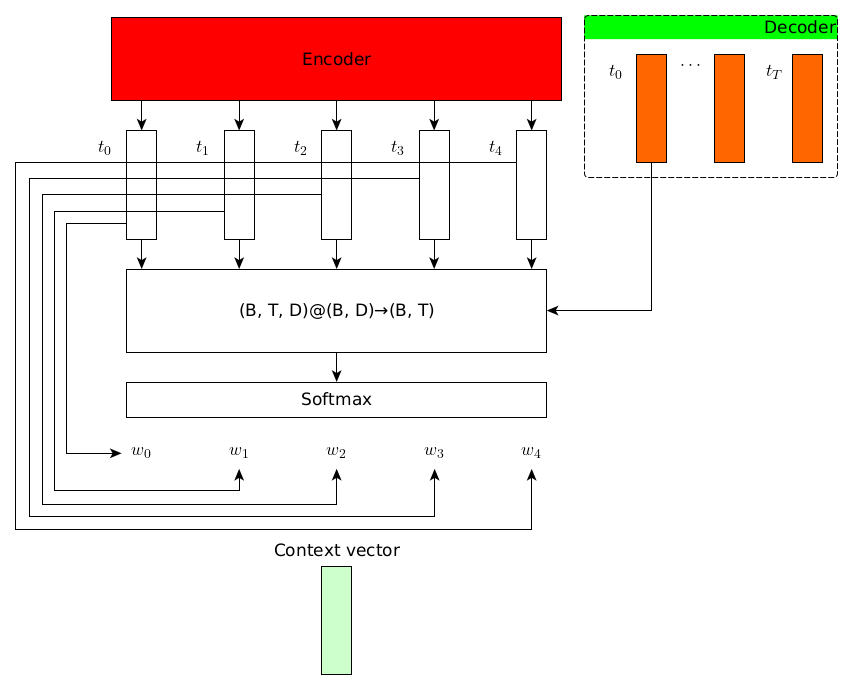

#### Нормировка в `ScaledDotProductAttention`
---

В классическом **dot-product attention** (Luong) оценка внимания вычисляется как скалярное произведение между векторами запроса (**query**) и ключа (**key**):

$$
e_{ij} = q_i^\top k_j
$$

Однако, когда размерность векторов $d_k$ становится большой (например, 512 или 1024), значения $e_{ij}$ могут иметь **большую дисперсию**.  
После этого на них применяется `softmax`:

$$
\alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{t} \exp(e_{it})}
$$

Проблема в том, что при больших $e_{ij}$ экспонента становится **очень крутой**, и `softmax` превращается почти в **"жёсткий максимум"** —  
внимание концентрируется на одном элементе, а градиенты для остальных становятся почти нулевыми.  
Это **затрудняет обучение** и делает модель нестабильной.

---

Авторы трансформера предложили **нормировать** скалярное произведение, разделив его на корень из размерности ключей:

$$
e_{ij} = \frac{q_i^\top k_j}{\sqrt{d_k}}
$$

Таким образом, если $q_i$ и $k_j$ — случайные векторы с нулевым средним и дисперсией 1, то дисперсия скалярного произведения $ q_i^\top k_j $ пропорциональна $ d_k $.  
Деление на $\sqrt{d_k}$ **стабилизирует распределение значений** $e_{ij}$, удерживая их в умеренных пределах.

---

- Уменьшает разброс значений $ e_{ij} $
- Делает softmax более **равномерным** (не "выстреливает" в один элемент)
- Улучшает **градиентный поток** при обучении
- Повышает **стабильность** и **скорость сходимости**

In [17]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, encoder_dim):
        super().__init__()
        self.scale = encoder_dim ** 0.5

    def forward(self, decoder_hidden, encoder_outputs):
        # decoder_hidden: (B, H)
        # encoder_outputs: (B, T, H)
        scores = torch.bmm(
            encoder_outputs,
            decoder_hidden.unsqueeze(2)
        ).squeeze(2) / self.scale  # (B, T)
        attn_weights = F.softmax(scores, dim=1)
        return attn_weights

In [18]:
batch_size, seq_len = 1, 10
hidden_dim = 32
# Fake encoder and decoder states
encoder_outputs = torch.randn(batch_size, seq_len, hidden_dim, requires_grad=True)
decoder_hidden = torch.randn(batch_size, hidden_dim, requires_grad=True)
# Instantiate and run attention
attention = ScaledDotProductAttention(hidden_dim)
attn_weights = attention(decoder_hidden, encoder_outputs)
# ---- Assertions ----
print("Attention output shape:", attn_weights.shape)  # (B, T)
assert attn_weights.shape == (batch_size, seq_len), "Output shape mismatch"
assert torch.allclose(attn_weights.sum(dim=1), torch.ones(batch_size), atol=1e-5), "Softmax normalization failed"
assert attn_weights.requires_grad, "Gradients not enabled"
# ---- Gradient check ----
attn_weights.sum().backward()
for name, param in attention.named_parameters():
    assert param.grad is not None, f"No gradient for parameter {name}"
print("✅ ScaledDotProductAttention passed all tests.")

Attention output shape: torch.Size([1, 10])
✅ ScaledDotProductAttention passed all tests.


| Характеристика                        | **Bahdanau Attention (Additive)**                                                                 | **Luong Attention (Multiplicative)**                                                        | **Scaled Dot-Product Attention (Transformer)**                  |
| :------------------------------------ | :------------------------------------------------------------------------------------------------ | :------------------------------------------------------------------------------------------ | :-------------------------------------------------------------- |
| **Авторы и год**                      | Bahdanau et al., 2014 — *"Neural Machine Translation by Jointly Learning to Align and Translate"* | Luong et al., 2015 — *"Effective Approaches to Attention-based Neural Machine Translation"* | Vaswani et al., 2017 — *"Attention is All You Need"*            |
| **Тип внимания**                      | Аддитивное (additive)                                                                             | Мультипликативное (dot/general)                                                             | Масштабированное скалярное произведение (scaled dot-product)    |
| **Формула оценки (score)**            | $ e_{t,s} = v_a^T \tanh(W_h h_s + W_s s_{t-1}) $                                                  | $ e_{t,s} = s_t^T W_a h_s $ или $ s_t^T h_s $                                               | $ e_{t,s} = \frac{s_t^T h_s}{\sqrt{d_k}} $                      |
| **Тип операции**                      | Сложение (additive combination)                                                                   | Умножение (dot product)                                                                     | Умножение с масштабированием                                    |
| **Нелинейность**                      | Есть (`tanh`)                                                                                     | Нет                                                                                         | Нет                                                             |
| **Параметры**                         | Больше (доп. линейные слои + вектор v)                                                            | Меньше                                                                                      | Минимум (только размерность d)                                  |
| **Скорость вычислений**               | Медленнее                                                                                         | Быстрее                                                                                     | Самая быстрая (параллелизуется на GPU)                          |
| **Гибкость выравнивания (alignment)** | Высокая — может сравнивать вектора из разных пространств                                          | Требует схожести пространств энкодера и декодера                                            | Работает в любом пространстве (через линейные проекции Q, K, V) |
| **Стабильность обучения**             | Высокая, но медленная сходимость                                                                  | Быстрая, но чувствительна к масштабу скрытых состояний                                      | Очень стабильная благодаря делению на $\sqrt{d_k}$              |
| **Интерпретация**                     | "Нейросетевое" вычисление совместимости                                                           | Геометрическое сходство (угол между векторами)                                              | Нормализованная мера сходства (контрастная оценка)              |
| **Использование в моделях**           | Классические `seq2seq RNN`, ранние `NMT`                                                              | Поздние `seq2seq`, `CNN+RNN` гибриды                                                            | `Transformer`, `BERT`, `GPT`, `ViT` и почти все современные архитектуры |
| **Типичная область**                  | Машинный перевод, распознавание речи                                                              | Машинный перевод, OCR, Captioning                                                           | Любая область: NLP, CV, Audio                                   |
| **Сложность реализации**              | Средняя (нужно больше слоёв)                                                                      | Простая                                                                                     | Простая, но требует Q/K/V проекций                              |
| **Интуитивная идея**                  | "Узнать, насколько хорошо состояния подходят друг другу"                                          | "Измерить похожесть состояний"                                                              | "Взвесить зависимости на основе нормализованной похожести"      |


`CRNN_Decoder`

Генерирует выходную последовательность символов на основе признаков изображения и внимания.

In [19]:
# --- CRNN Decoder ---
class CRNN_Decoder(nn.Module):
    def __init__(self, hidden_size, alphabet_size, embedding_dim=128, attention_type="scaled_dot"):
        """
        Args:
            hidden_size: размер скрытого состояния GRU
            alphabet_size: размер словаря (число возможных символов)
            embedding_dim: размер эмбеддинга входных токенов
            attention_type: 'bahdanau', 'luong' или 'scaled_dot'
        """
        super().__init__()
        self.embedding = nn.Embedding(alphabet_size, embedding_dim)

        # Выбор типа внимания
        attention_type = attention_type.lower()
        if attention_type == "bahdanau":
            self.attention = BahdanauAttention(hidden_size * 2, hidden_size * 2)
        elif attention_type == "luong":
            self.attention = LuongAttention(hidden_size * 2, hidden_size * 2)
        elif attention_type == "scaled_dot":
            self.attention = ScaledDotProductAttention(hidden_size * 2)
        else:
            raise ValueError(f"Unsupported attention type: {attention_type}")

        self.gru = nn.GRU(embedding_dim + hidden_size * 2, hidden_size * 2, batch_first=True)
        self.out = nn.Linear(hidden_size * 2, alphabet_size)
        self.attention_type = attention_type

    def forward(self, targets, encoder_outputs, hidden, teacher_forcing_ratio=0.5):
        batch_size, max_len = targets.size()
        outputs = []
        input_token = targets[:, 0].unsqueeze(1)  # <SOS>

        for t in range(1, max_len):
            embedded = self.embedding(input_token)  # (B, 1, E)

            # Внимание
            attn_weights = self.attention(hidden[-1], encoder_outputs)        # (B, T)
            context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs)   # (B, 1, H)

            # GRU шаг
            rnn_input = torch.cat((embedded, context), dim=2)                 # (B, 1, E + H)
            output, hidden = self.gru(rnn_input, hidden)                      # (B, 1, H)
            logits = self.out(output.squeeze(1))                              # (B, V)
            outputs.append(logits)

            # Teacher Forcing
            teacher_force = torch.rand(1).item() < teacher_forcing_ratio
            top1 = logits.argmax(1).unsqueeze(1)
            input_token = targets[:, t].unsqueeze(1) if teacher_force else top1

        return torch.stack(outputs, dim=1)  # (B, T-1, V)

    def generate(self, encoder_outputs, hidden, sos_idx=0, eos_idx=1, max_len=30):
        input_token = torch.tensor([[sos_idx]], device=encoder_outputs.device)
        outputs, weights = [], []
        
        for _ in range(max_len):
            embedded = self.embedding(input_token)                           # (1, 1, E)
            attn_weights = self.attention(hidden[-1], encoder_outputs)       # (1, T)
            context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs)  # (1, 1, H)
            rnn_input = torch.cat((embedded, context), dim=2)                # (1, 1, E + H)
            output, hidden = self.gru(rnn_input, hidden)
            logits = self.out(output.squeeze(1))                             # (1, V)
            top1 = logits.argmax(1)
            outputs.append(top1.item())
            weights.append(attn_weights.squeeze(0))
            
            if top1.item() == eos_idx:
                break
            input_token = top1.unsqueeze(1)

        weights = torch.stack(weights, 0)
        
        return outputs, weights.detach().cpu().numpy()


`RecognitionModel`

Объединяет энкодер и декодер в полную модель.

In [20]:
class RecognitionModel(nn.Module):
    def __init__(self, input_channels, input_height, hidden_size, alphabet_size, embedding_dim=128, attention_type="luong"):
        super(RecognitionModel, self).__init__()
        self.encoder = CRNN_Encoder(input_channels, hidden_size, input_height)
        self.decoder = CRNN_Decoder(hidden_size, alphabet_size, embedding_dim, attention_type)

    def forward(self, images, targets, teacher_forcing_ratio=0.5):
        encoder_outputs, (hn, _) = self.encoder(images)
        # Объединяем двунаправленные скрытые состояния
        hidden = torch.cat([hn[-2], hn[-1]], dim=1).unsqueeze(0)  # (1, B, 2H)
        return self.decoder(targets, encoder_outputs, hidden, teacher_forcing_ratio)

    def generate(self, image, sos_idx=0, eos_idx=1, max_len=30):
        encoder_outputs, (hn, _) = self.encoder(image.unsqueeze(0))
        hidden = torch.cat([hn[-2], hn[-1]], dim=1).unsqueeze(0)  # (1, 1, 2H)
        return self.decoder.generate(encoder_outputs, hidden, sos_idx, eos_idx, max_len)

Инициализируем параметры модели и процесса тренировки

In [21]:
input_channels, input_height, input_width = 3, 32, 160
hidden_size = 256 
max_len = 11

teacher_forcing_ratio = 0.5
learning_rate = 0.001
num_epochs = 5

Реализуем процесс тренировки модели

In [22]:
from collections import defaultdict
from colorama    import Fore, Style

import colorama

colorama.init(autoreset=True)

attention_type_s = ["bahdanau", "luong", "scaled_dot"]

total_loss_ss = defaultdict(list)
accuracy_ss   = defaultdict(list)

for attention_type in attention_type_s:
    banner = f"{'='*20} {attention_type.upper()} ATTENTION {'='*20}"
    print(Fore.CYAN + Style.BRIGHT + banner)
    print(Style.RESET_ALL)
    
    # Модель, функция потерь, оптимизатор
    model = RecognitionModel(input_channels, input_height, hidden_size, alphabet_size, attention_type=attention_type).cuda()
    criterion = nn.CrossEntropyLoss(ignore_index=sos_idx)  # ignore padding/SOS
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    # Цикл тренировки
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        total_correct = 0
        total_chars = 0
        
        for images, targets, texts in train_dataloader:
            images  = images.cuda()
            targets = targets.cuda()
            
            optimizer.zero_grad()
            outputs = model(images, targets, teacher_forcing_ratio=teacher_forcing_ratio)  # (B, T-1, V)
            
            # Целевая строка без учета <SOS> (первая колонка)
            target_seq = targets[:, 1:]  # (B, T-1)
            loss = criterion(outputs.view(-1, alphabet_size), target_seq.reshape(-1))
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()

            # Вычисления точности
            predictions = outputs.argmax(dim=-1)  # (B, T-1)
            correct = (predictions == target_seq).sum().item()
            total_correct += correct
            total_chars   += target_seq.numel()
        
        avg_loss = total_loss / len(train_dataloader)
        accuracy = total_correct / total_chars

        total_loss_ss[attention_type].append(avg_loss)
        accuracy_ss  [attention_type].append(accuracy)
        print(f"Epoch {epoch+1}/{num_epochs} - Loss: {avg_loss:.4f} - Accuracy: {accuracy:.4f}")

        torch.save(model.state_dict(), f"model_{attention_type}.pth")

==================== BAHDANAU ATTENTION ====================

Epoch 1/5 - Loss: 1.8590 - Accuracy: 0.3403
Epoch 2/5 - Loss: 0.8238 - Accuracy: 0.7120
Epoch 3/5 - Loss: 0.1075 - Accuracy: 0.9686
Epoch 4/5 - Loss: 0.0441 - Accuracy: 0.9883
Epoch 5/5 - Loss: 0.0300 - Accuracy: 0.9921
==================== LUONG ATTENTION ====================

Epoch 1/5 - Loss: 1.8546 - Accuracy: 0.3442
Epoch 2/5 - Loss: 1.1329 - Accuracy: 0.6008
Epoch 3/5 - Loss: 0.7197 - Accuracy: 0.7562
Epoch 4/5 - Loss: 0.2735 - Accuracy: 0.9227
Epoch 5/5 - Loss: 0.1371 - Accuracy: 0.9649
==================== SCALED_DOT ATTENTION ====================

Epoch 1/5 - Loss: 1.8803 - Accuracy: 0.3334
Epoch 2/5 - Loss: 0.6786 - Accuracy: 0.7569
Epoch 3/5 - Loss: 0.2792 - Accuracy: 0.9012
Epoch 4/5 - Loss: 0.0321 - Accuracy: 0.9911
Epoch 5/5 - Loss: 0.0150 - Accuracy: 0.9958


Визуализируем промежуточные результаты

In [37]:
# Create subplots: one for loss, one for accuracy
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Training Loss", "Training Accuracy"),
    horizontal_spacing=0.15
)

# Add traces for each attention type
for attention_type in attention_type_s:
    # Loss plot
    fig.add_trace(
        go.Scatter(
            y=total_loss_ss[attention_type],
            x=list(range(1, len(total_loss_ss[attention_type]) + 1)),
            mode="lines+markers",
            name=f"{attention_type} - loss"
        ),
        row=1, col=1
    )

    # Accuracy plot
    fig.add_trace(
        go.Scatter(
            y=accuracy_ss[attention_type],
            x=list(range(1, len(accuracy_ss[attention_type]) + 1)),
            mode="lines+markers",
            name=f"{attention_type} - acc"
        ),
        row=1, col=2
    )

# Update layout
fig.update_layout(
    title_text="Training Progress for Different Attention Mechanisms",
    title_x=0.5,
    width=1000,
    height=400,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.2,
        xanchor="center",
        x=0.5
    )
)

fig.update_xaxes(title_text="Epoch", row=1, col=1)
fig.update_yaxes(title_text="Loss",  row=1, col=1)

fig.update_xaxes(title_text="Epoch", row=1, col=2)
fig.update_yaxes(title_text="Accuracy", row=1, col=2)

fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [26]:
# Create subplots: one for loss, one for accuracy
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Training Loss", "Training Accuracy"),
    horizontal_spacing=0.15
)

# Add traces for each attention type
for attention_type in attention_type_s:
    # Loss plot
    fig.add_trace(
        go.Scatter(
            y=total_loss_ss[attention_type],
            x=list(range(1, len(total_loss_ss[attention_type]) + 1)),
            mode="lines+markers",
            name=f"{attention_type} - loss"
        ),
        row=1, col=1
    )

    # Accuracy plot
    fig.add_trace(
        go.Scatter(
            y=accuracy_ss[attention_type],
            x=list(range(1, len(accuracy_ss[attention_type]) + 1)),
            mode="lines+markers",
            name=f"{attention_type} - acc"
        ),
        row=1, col=2
    )

# Update layout
fig.update_layout(
    title_text="Training Progress for Different Attention Mechanisms",
    title_x=0.5,
    width=1000,
    height=400,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.2,
        xanchor="center",
        x=0.5
    )
)

fig.update_xaxes(title_text="Epoch", row=1, col=1)
fig.update_yaxes(title_text="Loss",  row=1, col=1)

fig.update_xaxes(title_text="Epoch", row=1, col=2)
fig.update_yaxes(title_text="Accuracy", row=1, col=2)

fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

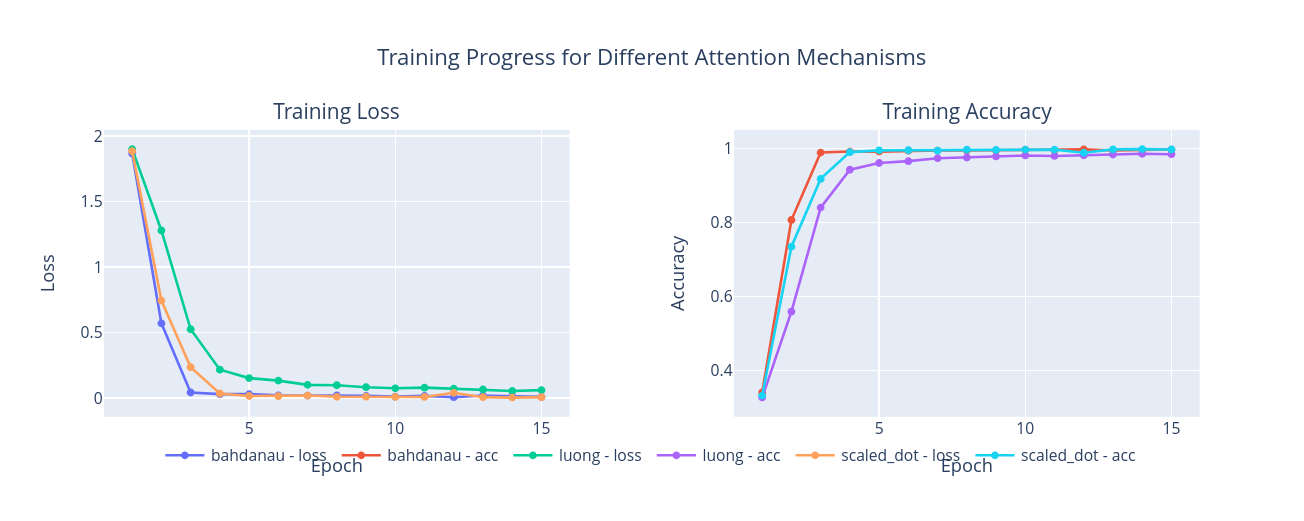

Реализуем процесс тестирования модели

In [29]:
model = RecognitionModel(input_channels, input_height, hidden_size, alphabet_size, attention_type="bahdanau").cuda()
model.load_state_dict(torch.load("model_bahdanau.pth", weights_only=True))
model.eval()
total_chars, total_correct               = 0, 0

prediction_index_s, ground_truth_index_s = [], []
prediction_text_s , ground_truth_text_s  = [], []
prediction_weights_s = []

with torch.no_grad():
    for images, targets, texts in val_dataloader:
        images  = images .cuda()
        targets = targets.cuda()
        for i in range(images.size(0)):
            # Генерируем предсказание
            pred_tokens, pred_weights = model.generate(images[i], sos_idx, eos_idx, max_len)
            
            # Удаляем <SOS> и все, что находится после <EOS> в целевой строке
            target_seq = targets[i].tolist()
            if eos_idx in target_seq:
                eos_pos = target_seq.index(eos_idx)
                target_seq = target_seq[1:eos_pos]  # Удаляем <SOS>, останавливаемся на символе <EOS>
            else:
                target_seq = target_seq[1:]  # no EOS found
            # Truncate prediction at EOS if exists
            if eos_idx in pred_tokens:
                eos_pos = pred_tokens.index(eos_idx)
                pred_tokens = pred_tokens[:eos_pos]
            # Accuracy per character
            min_len = min(len(pred_tokens), len(target_seq))
            correct = sum(p == t for p, t in zip(pred_tokens[:min_len], target_seq[:min_len]))
            total_correct += correct
            total_chars += len(target_seq)
            prediction_index_s .append(pred_tokens)
            ground_truth_index_s.append(target_seq )

            prediction_text_s  .append( ''.join([full_alphabet_i2s[i] for i in pred_tokens]) )
            ground_truth_text_s.append( ''.join([full_alphabet_i2s[i] for i in target_seq ]) )

            prediction_weights_s.append(pred_weights)
            
accuracy = total_correct / total_chars if total_chars > 0 else 0.0
print(f"Test Character Accuracy: {accuracy:.4f}")

Test Character Accuracy: 0.9876


Напечатаем некоторые предсказания и сравним с целевыми текстами

In [43]:
def plot_attention(attn_matrix, title="Attention Map"):
    """
    attn_matrix: numpy array of shape (T_dec, T_enc)
    After transposition:
        X-axis -> Decoder steps
        Y-axis -> Encoder steps
    """
    T_dec, T_enc = attn_matrix.shape

    # Transpose matrix so X = decoder steps, Y = encoder steps
    attn_matrix = attn_matrix.T   # shape: (T_enc, T_dec)

    fig = go.Figure(
        data=go.Heatmap(
            z=attn_matrix,
            colorscale="Viridis",
            showscale=True
        )
    )

    fig.update_layout(
        title=title,
        xaxis=dict(
            title="Decoder Time Step",
            tickmode="array",
            tickvals=list(range(T_dec)),
            ticktext=[str(i) for i in range(T_dec)]
        ),
        yaxis=dict(
            title="Encoder Time Step",
            tickmode="array",
            tickvals=list(range(T_enc)),
            ticktext=[str(i) for i in range(T_enc)]
        ),
        height=1200,
        width=600
    )

    fig.show()

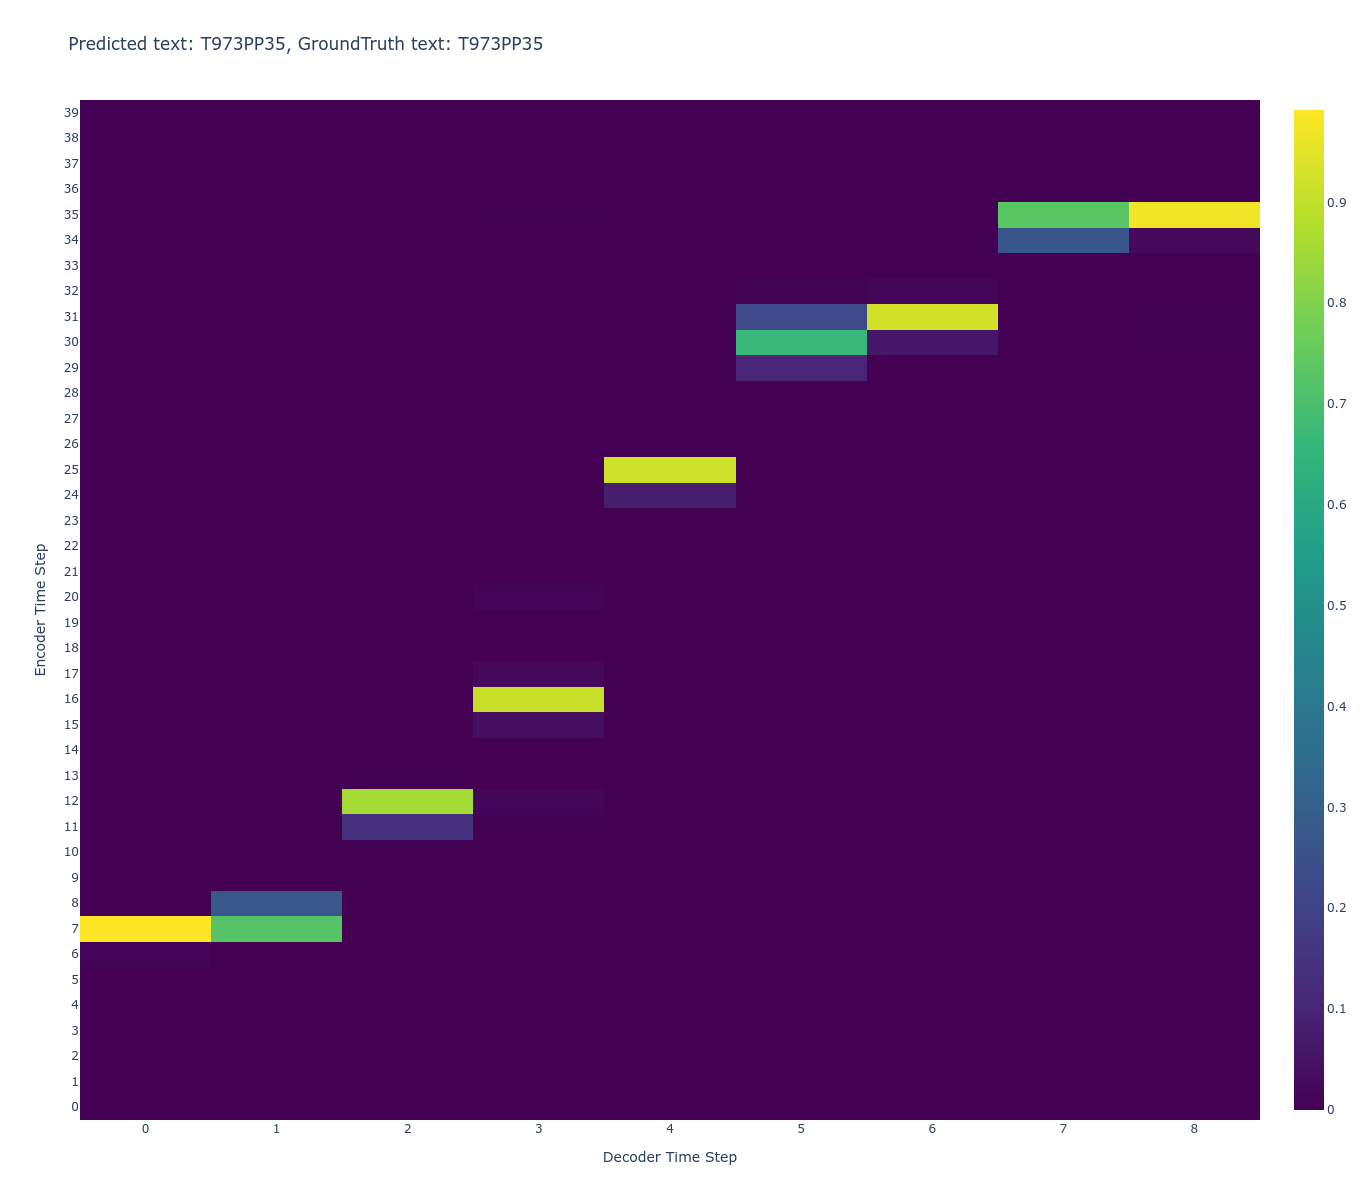

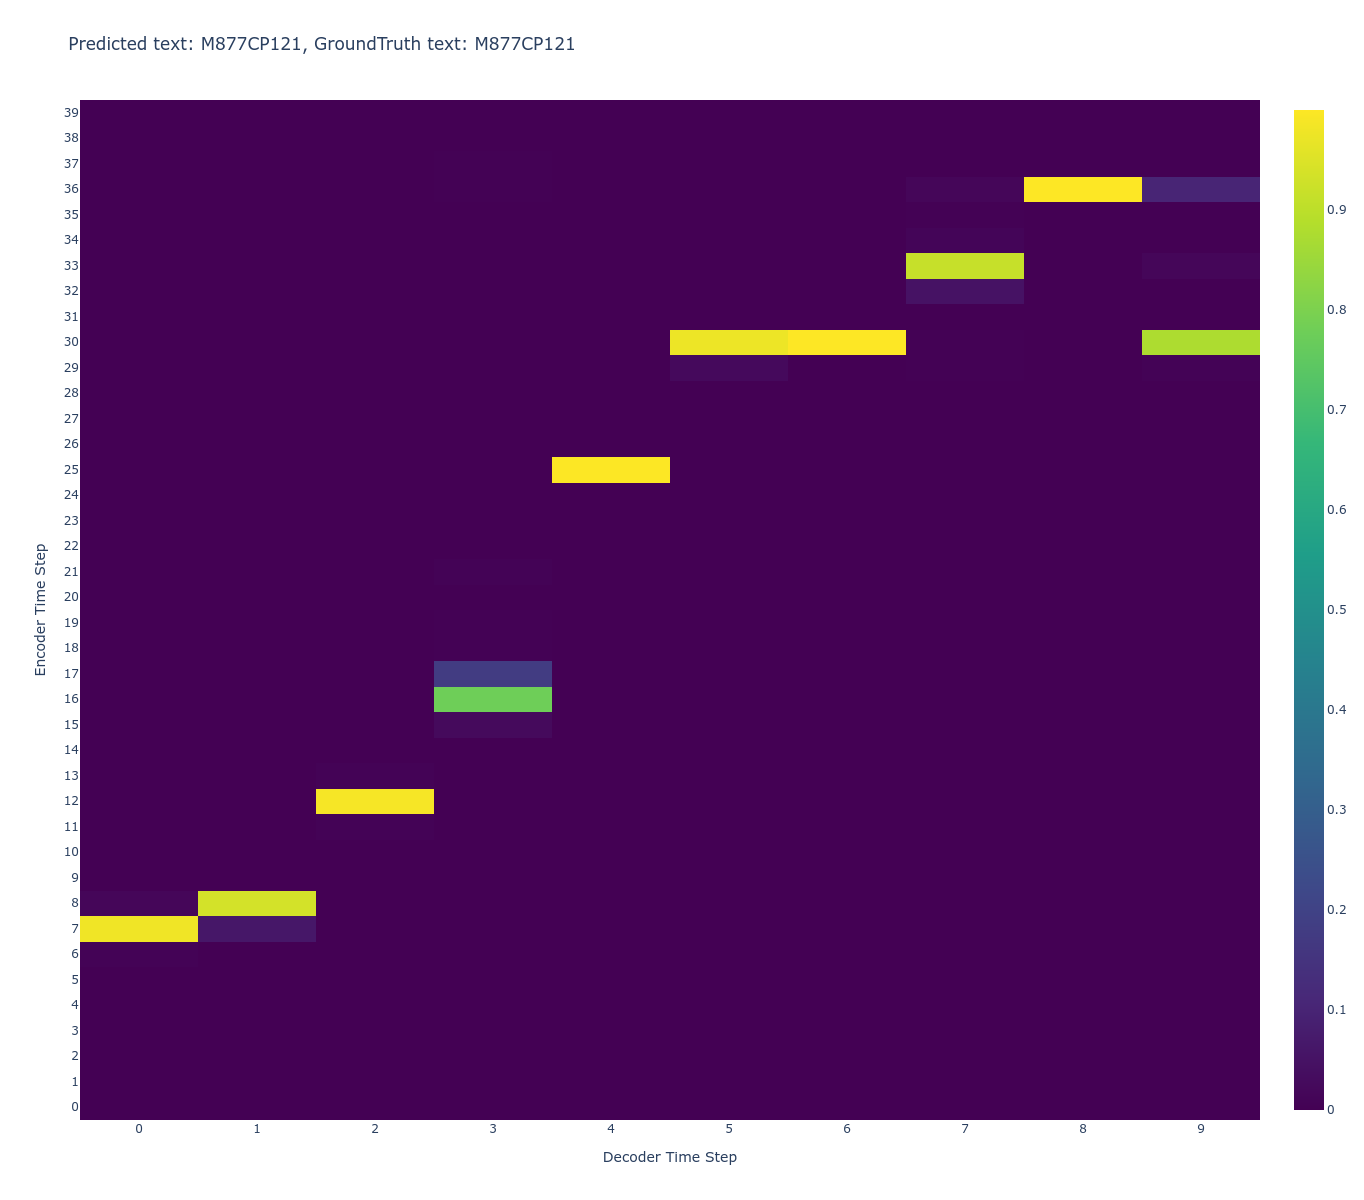

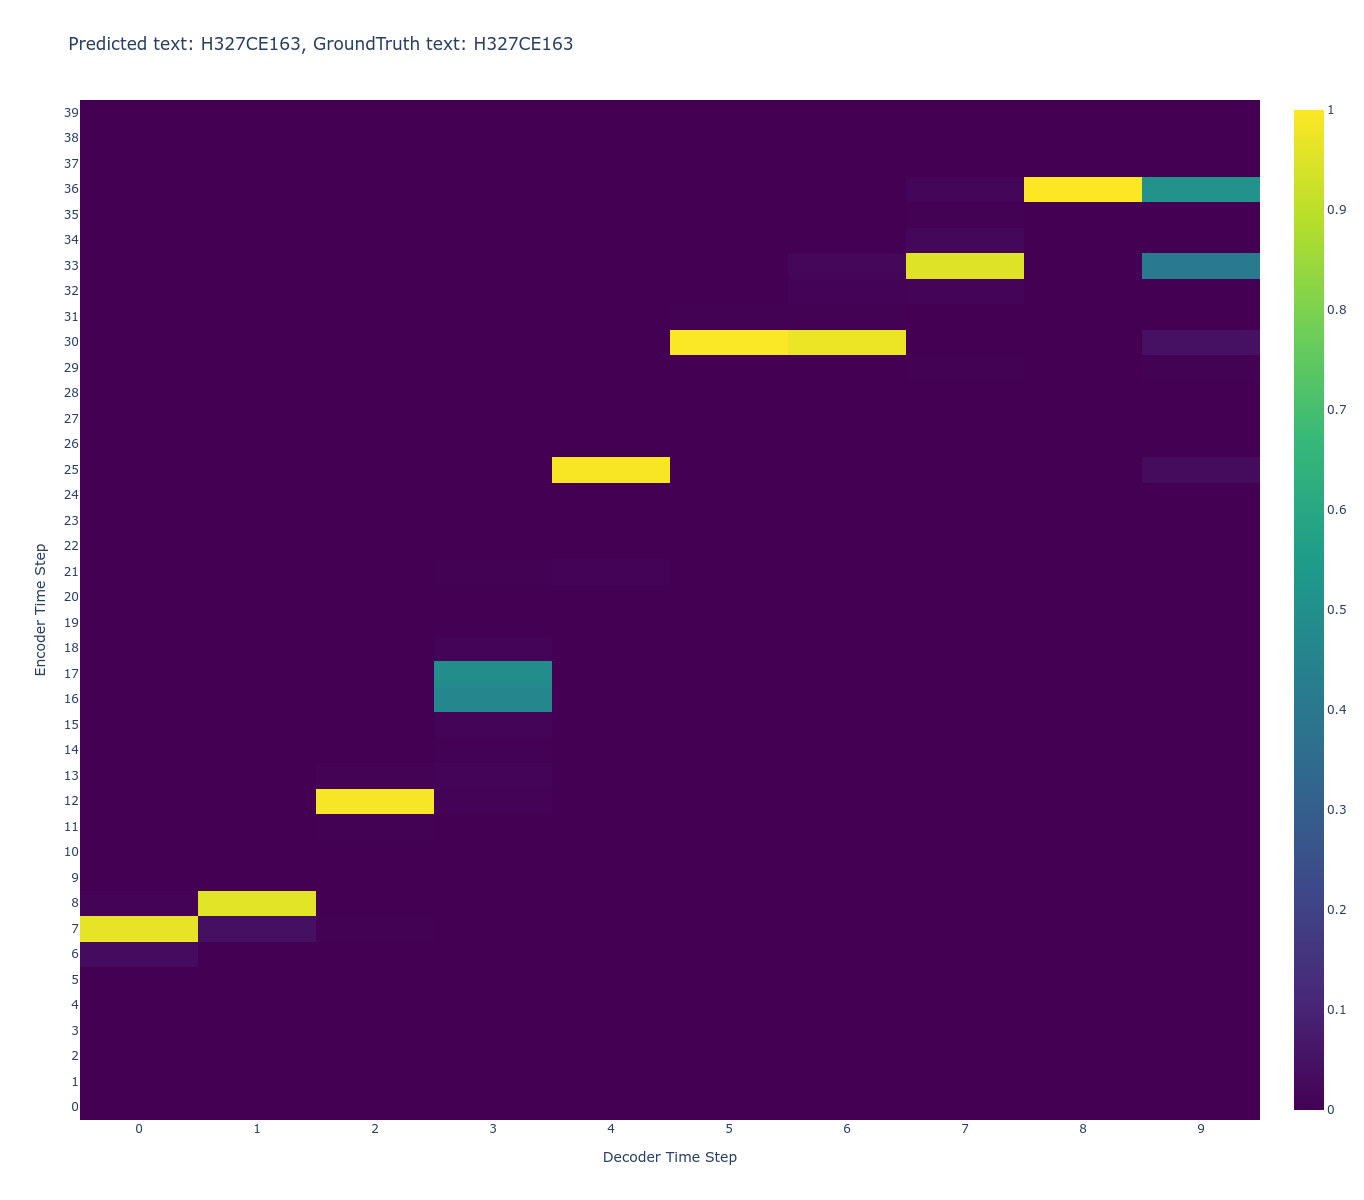

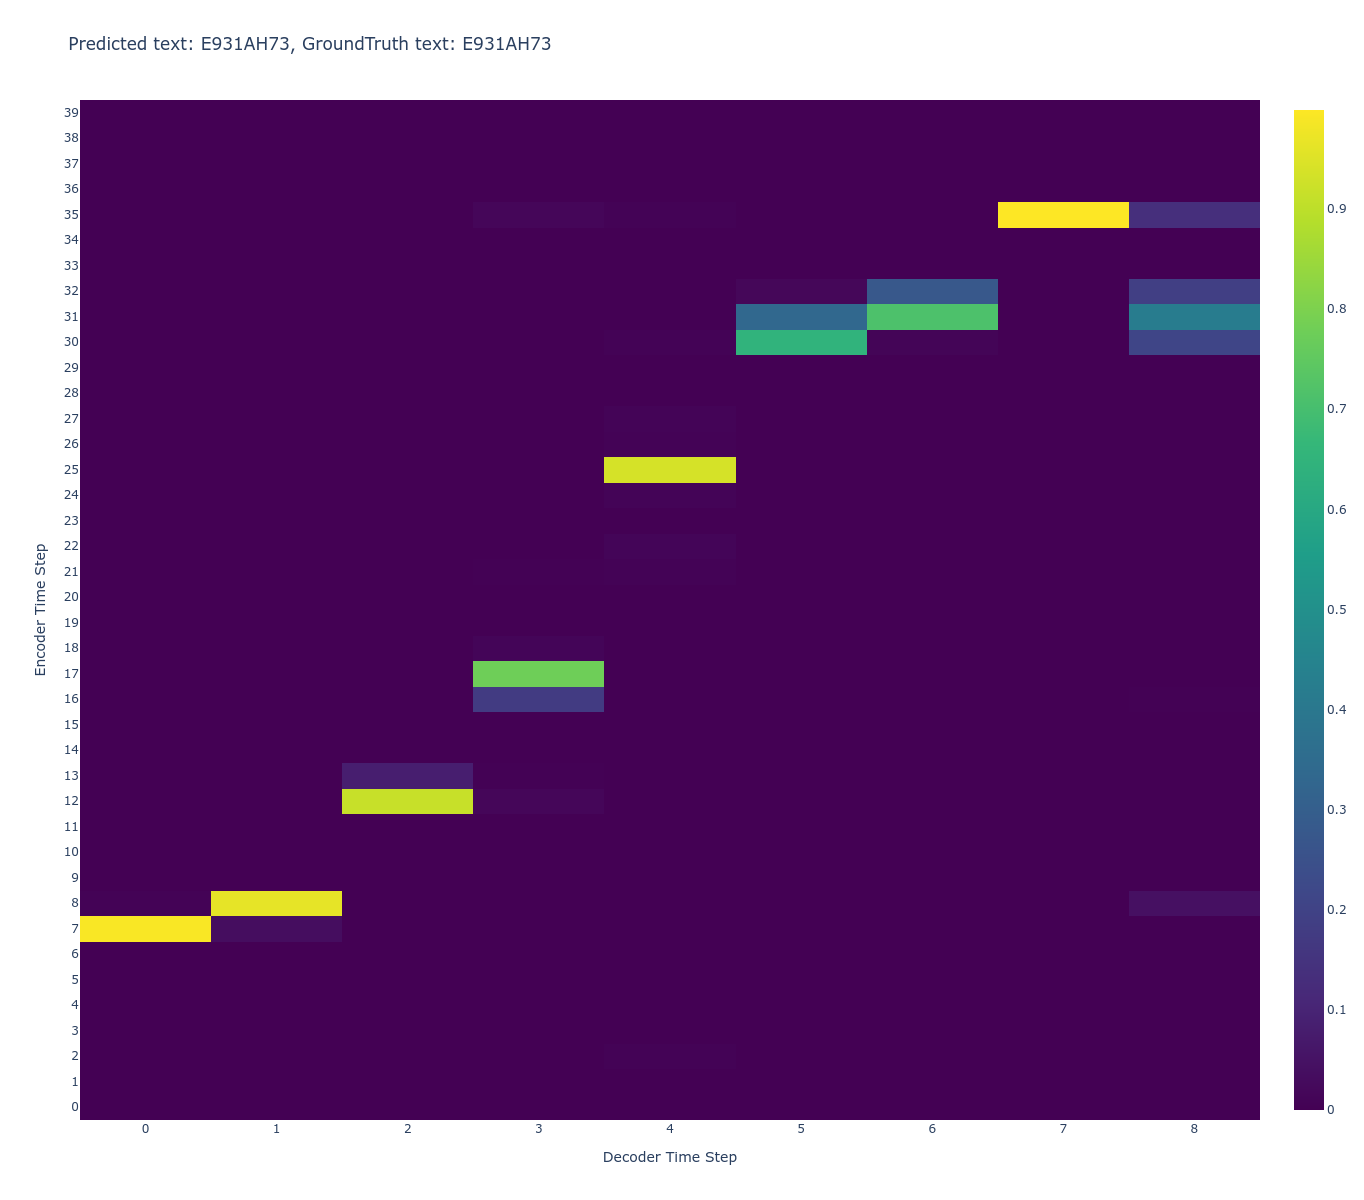

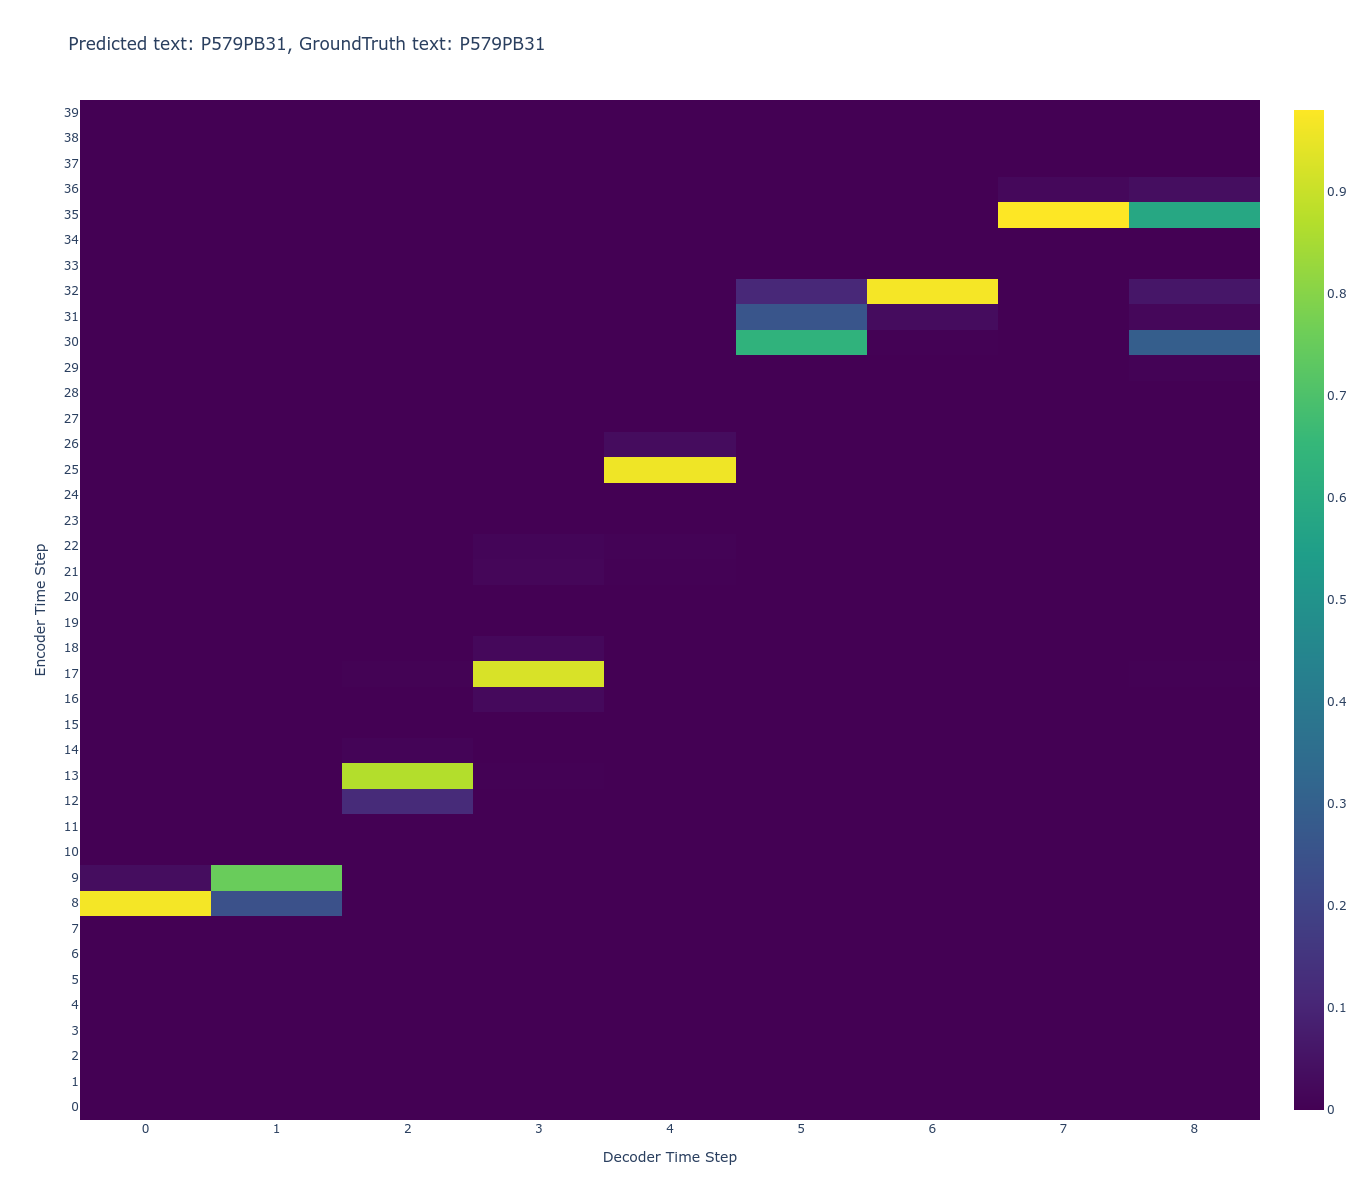

In [44]:
from random import sample

for prediction_text, ground_truth_text, prediction_weights in  sample( list(zip(prediction_text_s, ground_truth_text_s, prediction_weights_s)), k=5):
    plot_attention(prediction_weights, f'Predicted text: {prediction_text}, GroundTruth text: {ground_truth_text}')

### Наша модель работает!!!

### Бонус: Жадный поиск (Greedy Search) vs. Исчерпывающий поиск (Exhaustive Search) vs. Лучевой поиск (Beam Search)

`Общая постановка задачи`

Представим, что у нас есть задача генерации последовательности $Y = (y_1, y_2, \cdots, y_T)$, где каждое $y_i$ — это элемент последовательности (например, слово). Наша модель выдает вероятность всей последовательности $P(Y|X)$, где X — это входные данные (например, исходное предложение). Наша цель — найти наиболее вероятную выходную последовательность:

$$Y* = \arg\max_Y P(Y|X)$$

`Исчерпывающий поиск (Exhaustive Search)`

Алгоритм исследует все возможные последовательности и возвращает последовательность, которая имеет максимальную общую вероятность $P(Y|X)$. Это точное решение задачи $\arg\max_Y P(Y|X)$. Он гарантированно находит глобальный максимум, однако вычислительно неосуществим для сколь-либо длинных последовательностей. Если размер словаря $V=1000$, а длина последовательности $T=10$, число вариантов равно $1000^10$.

`Жадный поиск (Greedy Search)`

Алгоритм на каждом шаге выбирает слово с наивысшей вероятностью на текущем шаге, не задумываясь о будущих последствиях.

- $t_1$ : $y_1^{*} = \arg\max_{y_1} P(y_1 | X)$
    
- $t_2$ : $y_2^{*} = \arg\max_{y_2} P(y_2 | X, y_1^{*})$

- $t_3$ : $y_2^{*} = \arg\max_{y_3} P(y_3 | X, y_1^{*}, y_2^{*})$

    ... и так далее.

Жадный поиск аппроксимирует полную вероятность последовательности $P(Y|X)$ как произведение максимумов условных вероятностей на каждом шаге:

$$P(Y|X) ≈ max_{y_1} P(y_1|X) \cdot max_{y_2} P(y_2|X, y_1^{*}) \cdot max_{y_3} P(y_3|X, y_1^{*}, y_2^{*}) \cdot ...$$

Он не ищет последовательность, максимизирующую общее произведение. Вместо этого он на каждом шаге максимизирует только один множитель этого произведения.

`Лучевой поиск (Beam Search)`

Это компромисс между двумя предыдущими методами. Лучевой поиск поддерживает k (ширина луча, beam width) наиболее перспективных гипотез на каждом шаге.

- Инициализация: Начинаем с $k$ самых вероятных первых слов ($y_1$)
- Расширение: Для каждой из $k$ гипотез рассматриваем все возможные следующие слова. Общее число гипотез становится $k × V$
- Отбор: Из всех этих $k × V$ гипотез мы выбираем $top-k$ с наибольшей суммарной вероятностью на данный момент
- Повтор: Шаги 2 и 3 повторяются до тех пор, пока все гипотезы не завершатся (например, специальным токеном $<eos>$)

Лучевой поиск аппроксимирует поиск глобального максимума, но работает не со всем пространством, а с подмножеством из k наиболее вероятных кандидатов.

Он ищет последовательность, которая максимизирует не каждый шаг по отдельности, а совместную вероятность накопленного пути для $k$ кандидатов:

$$score(Y_{1:t}) = P(y₁, y₂, ..., y_t | X) = P(y_1|X) \cdot P(y_2|X, y_1) \cdot ... \cdot P(y_t|X, y_1, ..., y_{t-1})$$

На каждом шаге он отбирает $k$ путей с наибольшим $score$.

`Общий вывод`

Можно думать об этих методах как о разных стратегиях аппроксимации сложной задачи поиска максимума в вероятностном пространстве:

Исчерпывающий поиск — это точное вычисление $\arg\max$

Жадный поиск — это предположение, что цепь Маркова короткая, и можно оптимизировать каждый шаг независимо (крайняя форма аппроксимации)

Лучевой поиск — это умная эвристика, которая исследует пространство состояний, сохраняя набор наиболее вероятных траекторий (последовательностей), а не просто отдельных состояний